# RQ2: The Energy Cost of Accuracy

This notebook analyses how much energy the accuracy of the models costs, and how that cost changed across releases.

The process consists of:
1. **Fixed Budgets and Targets**: Following, over time, the best accuracy within an energy budget and the lowest energy for an accuracy target.
2. **Year-End Values**: Listing the values of both views at the end of each year.
3. **Size Categories**: Repeating both views within each size category.
4. **Marginal Cost**: Computing the energy of each additional accuracy point along the Pareto front.
5. **Cost Between Successive Releases**: Computing the change of accuracy and of energy between each instruct run and the previous release of its family.
6. **Accuracy and Energy of the Instruct Runs**: Correlating the accuracy of the instruct runs with their energy per question, its two factors and their size, over the whole period and before and since June 2025.
7. **Key Values**: Printing the main values of this notebook.

The Pareto front of each year and the best accuracy within every energy budget are in `02-rq1-evolution.ipynb`.

### Setup & Imports
We load the tables built by `00-dataset.ipynb` and the chart helpers of `common.py`. The energy budgets and the accuracy targets are set in `common.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from common import (
    ACCURACY_TARGETS,
    BUDGET_COLORS,
    BUDGETS_KJ,
    CATEGORY_ORDER,
    FAMILY_ORDER,
    category_panels,
    chance_level,
    format_year_axis,
    legend_handles,
    load_model_runs,
    load_questions,
    pareto_front,
    percent_axis,
    plain_log_axis,
    save_chart,
    scatter_model_runs,
    TARGET_COLORS,
    short_name,
)

model_runs = load_model_runs().sort_values(["release_date", "model_run"]).reset_index(drop=True)
questions = load_questions(model_runs)

CHANCE_LEVEL = chance_level(questions)
FAMILIES = [family for family in FAMILY_ORDER if family in set(model_runs["family"])]
YEARS = sorted(model_runs["release_date"].dt.year.unique())
LAST_DATE = model_runs["release_date"].max()
# Lines of different widths stay visible where they overlap
LEVEL_WIDTHS = [4.2, 3.2, 2.2, 1.2]

print(f"Model runs: {len(model_runs)}   release dates: {model_runs['release_date'].min().date()} to {LAST_DATE.date()}")
print(f"Energy budgets (kJ per question): {BUDGETS_KJ}   accuracy targets: {ACCURACY_TARGETS}")

Model runs: 53   release dates: 2023-07-13 to 2026-03-02
Energy budgets (kJ per question): [0.5, 1, 2, 5]   accuracy targets: [0.4, 0.5, 0.6, 0.7]


### 1. Fixed Budgets and Targets
We follow two values over the release dates. The first is the best accuracy among the model runs released so far that use at most a given GPU energy per question (the budget). The second is the lowest GPU energy per question among the model runs released so far that reach a given accuracy (the target). A marker shows each model run that improved the value. The energy budgets are drawn in orange and the accuracy targets in blue, from the lowest (lightest) to the highest (darkest).

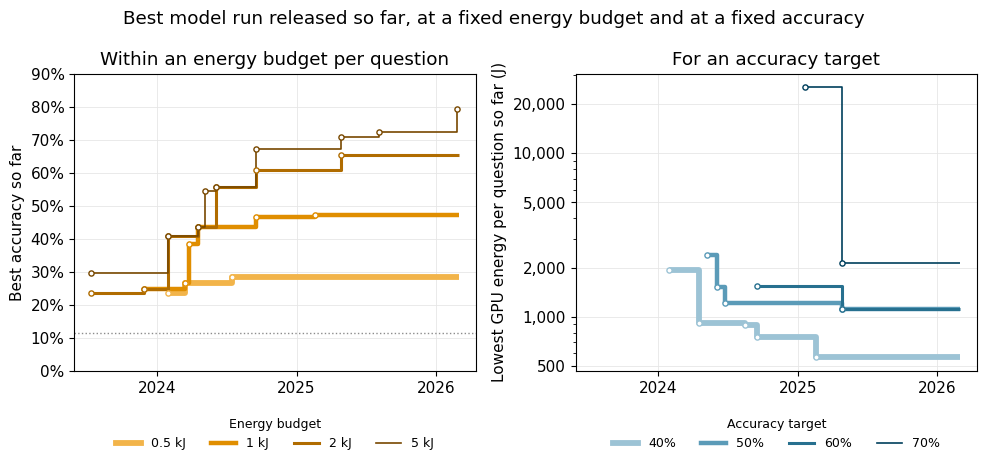

In [2]:
def best_accuracy_within(runs, budget_kj):
    # Model runs that raised the best accuracy within the budget, by release date
    within = runs[runs["gpu_joules_per_question"] <= budget_kj * 1000]
    records = within[within["accuracy"] > within["accuracy"].cummax().shift(fill_value=-np.inf)]
    return records.drop_duplicates("release_date", keep="last")


def lowest_energy_for(runs, target):
    # Model runs that lowered the lowest energy among those that reach the target, by release date
    reaching = runs[runs["accuracy"] >= target]
    records = reaching[reaching["gpu_joules_per_question"] < reaching["gpu_joules_per_question"].cummin().shift(fill_value=np.inf)]
    return records.drop_duplicates("release_date", keep="last")


def plot_levels(ax, runs, levels, colors, records_of, column):
    # One step line per level, from the first model run that qualifies to the last release date
    for level, color, width in zip(levels, colors, LEVEL_WIDTHS):
        records = records_of(runs, level)
        if records.empty:
            continue
        dates = list(records["release_date"]) + [LAST_DATE]
        values = list(records[column]) + [records[column].iloc[-1]]
        ax.step(dates, values, where="post", color=color, linewidth=width, solid_capstyle="butt", zorder=2)
        ax.scatter(records["release_date"], records[column], s=14, color="w", edgecolors=color, linewidth=1, zorder=3)
    format_year_axis(ax)


def level_handles(colors, labels):
    return [Line2D([], [], color=color, linewidth=width, label=label) for color, width, label in zip(colors, LEVEL_WIDTHS, labels)]


BUDGET_LABELS = [f"{budget:g} kJ" for budget in BUDGETS_KJ]
TARGET_LABELS = [f"{target:.0%}" for target in ACCURACY_TARGETS]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
plot_levels(axes[0], model_runs, BUDGETS_KJ, BUDGET_COLORS, best_accuracy_within, "accuracy")
axes[0].axhline(CHANCE_LEVEL, color="0.55", linewidth=1, linestyle=":")
axes[0].set_ylim(0, 0.9)
percent_axis(axes[0].yaxis)
axes[0].set_ylabel("Best accuracy so far")
axes[0].set_title("Within an energy budget per question")
axes[0].legend(handles=level_handles(BUDGET_COLORS, BUDGET_LABELS), title="Energy budget", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9, title_fontsize=9, frameon=False)

plot_levels(axes[1], model_runs, ACCURACY_TARGETS, TARGET_COLORS, lowest_energy_for, "gpu_joules_per_question")
axes[1].set_yscale("log")
plain_log_axis(axes[1].yaxis)
axes[1].set_ylabel("Lowest GPU energy per question so far (J)")
axes[1].set_title("For an accuracy target")
axes[1].legend(handles=level_handles(TARGET_COLORS, TARGET_LABELS), title="Accuracy target", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9, title_fontsize=9, frameon=False)

for ax in axes:
    ax.set_xlim(model_runs["release_date"].min() - pd.Timedelta(days=45), LAST_DATE + pd.Timedelta(days=45))
fig.suptitle("Best model run released so far, at a fixed energy budget and at a fixed accuracy")
plt.tight_layout()
save_chart(fig, "rq2-fixed-budgets-and-targets")
plt.show()

The model runs that improved each value:

In [3]:
rows = []
for budget in BUDGETS_KJ:
    for _, run in best_accuracy_within(model_runs, budget).iterrows():
        rows.append({"View": f"Best accuracy within {budget:g} kJ", "Released": run["release_date"].date(), "Model run": short_name(run["model_run"]), "Category": run["category"], "Accuracy": round(run["accuracy"], 3), "GPU energy per question (J)": round(run["gpu_joules_per_question"])})
for target in ACCURACY_TARGETS:
    for _, run in lowest_energy_for(model_runs, target).iterrows():
        rows.append({"View": f"Lowest energy for an accuracy of {target:g}", "Released": run["release_date"].date(), "Model run": short_name(run["model_run"]), "Category": run["category"], "Accuracy": round(run["accuracy"], 3), "GPU energy per question (J)": round(run["gpu_joules_per_question"])})
records = pd.DataFrame(rows)
records.set_index(["View", "Released"])

Model run  \
View                                 Released                                   
Best accuracy within 0.5 kJ          2024-01-30               Qwen1.5-4B-Chat   
                                     2024-03-14        Qwen1.5-MoE-A2.7B-Chat   
                                     2024-07-16                 gemma-2-2b-it   
Best accuracy within 1 kJ            2023-11-29          deepseek-llm-7b-chat   
                                     2024-03-14        Qwen1.5-MoE-A2.7B-Chat   
                                     2024-03-26               gemma-1.1-7b-it   
                                     2024-04-17      Meta-Llama-3-8B-Instruct   
                                     2024-09-17           Qwen2.5-3B-Instruct   
                                     2025-02-19           Phi-4-mini-instruct   
Best accuracy within 2 kJ            2023-07-13            Llama-2-7b-chat-hf   
                                     2023-11-29          deepseek-llm-7b-chat   
                                     2024-01-30              Qwen1.5-14B-Chat   
                                     2024-04-17      Meta-Llama-3-8B-Instruct   
                                     2024-06-04             Qwen2-7B-Instruct   
                                     2024-09-16           Qwen2.5-7B-Instruct   
                                     2025-04-27                  Qwen3-8B (I)   
Best accuracy within 5 kJ            2023-07-13           Llama-2-13b-chat-hf   
                                     2024-01-30              Qwen1.5-14B-Chat   
                                     2024-04-17      Meta-Llama-3-8B-Instruct   
                                     2024-05-07      Phi-3-medium-4k-instruct   
                                     2024-06-04             Qwen2-7B-Instruct   
                                     2024-09-16          Qwen2.5-14B-Instruct   
                                     2025-04-27                 Qwen3-14B (I)   
                                     2025-08-05        Qwen3-4B-Instruct-2507   
                                     2026-02-27                Qwen3.5-9B (I)   
Lowest energy for an accuracy of 0.4 2024-01-30              Qwen1.5-14B-Chat   
                                     2024-04-17      Meta-Llama-3-8B-Instruct   
                                     2024-08-16         Phi-3.5-mini-instruct   
                                     2024-09-17           Qwen2.5-3B-Instruct   
                                     2025-02-19           Phi-4-mini-instruct   
Lowest energy for an accuracy of 0.5 2024-05-07      Phi-3-medium-4k-instruct   
                                     2024-06-04             Qwen2-7B-Instruct   
                                     2024-06-24                 gemma-2-9b-it   
                                     2025-04-27                  Qwen3-8B (I)   
Lowest energy for an accuracy of 0.6 2024-09-16           Qwen2.5-7B-Instruct   
                                     2025-04-27                  Qwen3-8B (I)   
Lowest energy for an accuracy of 0.7 2025-01-20  DeepSeek-R1-Distill-Qwen-14B   
                                     2025-04-27                 Qwen3-14B (I)   

                                                         Category  Accuracy  \
View                                 Released                                 
Best accuracy within 0.5 kJ          2024-01-30       Tiny/Mobile     0.237   
                                     2024-03-14  Standard/Desktop     0.266   
                                     2024-07-16       Tiny/Mobile     0.285   
Best accuracy within 1 kJ            2023-11-29        Small/Edge     0.247   
                                     2024-03-14  Standard/Desktop     0.266   
                                     2024-03-26        Small/Edge     0.384   
                                     2024-04-17        Small/Edge     0.435   
                                     2024-09-17       Tiny/Mobile     0.465   
                                     

### 2. Year-End Values
We list both values at the end of each year, with the model run that holds them. The last year only covers the releases until the last date of the study.

In [4]:
def at_year_end(records, year, column):
    until = records[records["release_date"].dt.year <= year]
    return None if until.empty else until.iloc[-1]


rows = []
for year in YEARS:
    for budget, label in zip(BUDGETS_KJ, BUDGET_LABELS):
        run = at_year_end(best_accuracy_within(model_runs, budget), year, "accuracy")
        rows.append({"Level": f"Within {label}", "Year": year, "Value": "-" if run is None else f"{run['accuracy']:.3f}", "Model run": "-" if run is None else short_name(run["model_run"])})
    for target, label in zip(ACCURACY_TARGETS, TARGET_LABELS):
        run = at_year_end(lowest_energy_for(model_runs, target), year, "gpu_joules_per_question")
        rows.append({"Level": f"Accuracy of {label}", "Year": year, "Value": "-" if run is None else f"{run['gpu_joules_per_question']:.0f} J", "Model run": "-" if run is None else short_name(run["model_run"])})
year_ends = pd.DataFrame(rows)

levels = [f"Within {label}" for label in BUDGET_LABELS] + [f"Accuracy of {label}" for label in TARGET_LABELS]
year_end_values = year_ends.pivot(index="Level", columns="Year", values="Value").loc[levels]
year_end_models = year_ends.pivot(index="Level", columns="Year", values="Model run").loc[levels]
year_end_values

Year,2023,2024,2025,2026
Level,,,,
Within 0.5 kJ,-,0.285,0.285,0.285
Within 1 kJ,0.247,0.465,0.470,0.470
Within 2 kJ,0.247,0.608,0.653,0.653
Within 5 kJ,0.297,0.672,0.723,0.793
Accuracy of 40%,-,752 J,564 J,564 J
Accuracy of 50%,-,1221 J,1111 J,1111 J
Accuracy of 60%,-,1539 J,1111 J,1111 J
Accuracy of 70%,-,-,2131 J,2131 J


In [5]:
year_end_models

Year,2023,2024,2025,2026
Level,,,,
Within 0.5 kJ,-,gemma-2-2b-it,gemma-2-2b-it,gemma-2-2b-it
Within 1 kJ,deepseek-llm-7b-chat,Qwen2.5-3B-Instruct,Phi-4-mini-instruct,Phi-4-mini-instruct
Within 2 kJ,deepseek-llm-7b-chat,Qwen2.5-7B-Instruct,Qwen3-8B (I),Qwen3-8B (I)
Within 5 kJ,Llama-2-13b-chat-hf,Qwen2.5-14B-Instruct,Qwen3-4B-Instruct-2507,Qwen3.5-9B (I)
Accuracy of 40%,-,Qwen2.5-3B-Instruct,Phi-4-mini-instruct,Phi-4-mini-instruct
Accuracy of 50%,-,gemma-2-9b-it,Qwen3-8B (I),Qwen3-8B (I)
Accuracy of 60%,-,Qwen2.5-7B-Instruct,Qwen3-8B (I),Qwen3-8B (I)
Accuracy of 70%,-,-,Qwen3-14B (I),Qwen3-14B (I)


### 3. Size Categories
We repeat both views with the model runs of each size category.

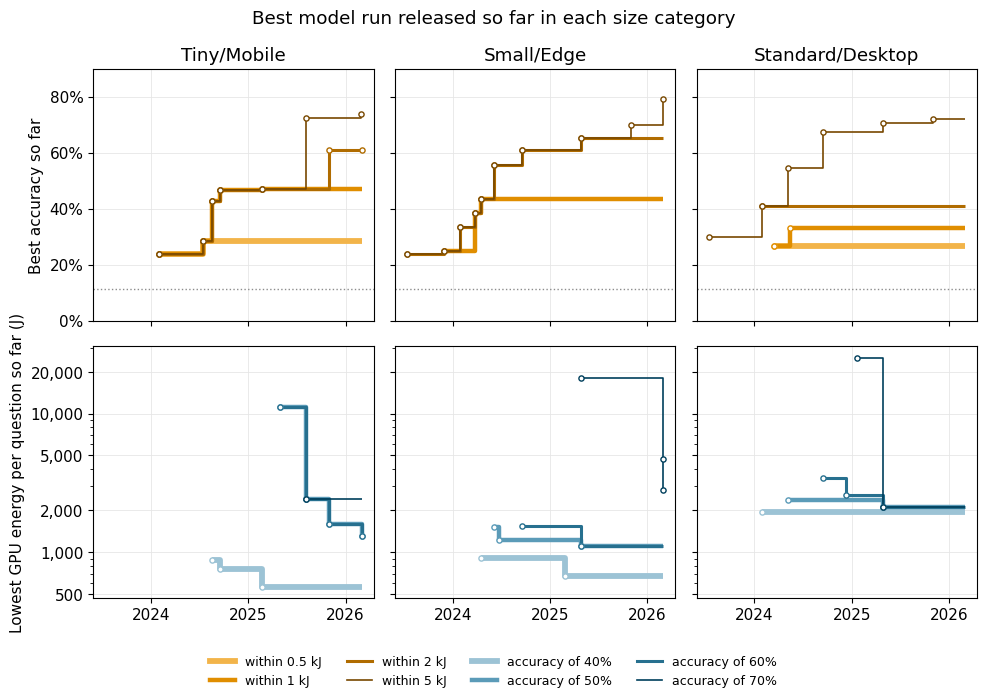

In [6]:
fig, axes = category_panels(nrows=2, figsize=(10, 7), sharex=True, sharey="row")
for column, category in enumerate(CATEGORY_ORDER):
    runs = model_runs[model_runs["category"] == category]
    plot_levels(axes[0][column], runs, BUDGETS_KJ, BUDGET_COLORS, best_accuracy_within, "accuracy")
    axes[0][column].axhline(CHANCE_LEVEL, color="0.55", linewidth=1, linestyle=":")
    axes[0][column].set_ylim(0, 0.9)
    percent_axis(axes[0][column].yaxis)
    plot_levels(axes[1][column], runs, ACCURACY_TARGETS, TARGET_COLORS, lowest_energy_for, "gpu_joules_per_question")
    axes[1][column].set_yscale("log")
    plain_log_axis(axes[1][column].yaxis)
    axes[1][column].set_xlim(model_runs["release_date"].min() - pd.Timedelta(days=45), LAST_DATE + pd.Timedelta(days=45))
axes[0][0].set_ylabel("Best accuracy so far")
axes[1][0].set_ylabel("Lowest GPU energy per question so far (J)")
handles = level_handles(BUDGET_COLORS, [f"within {label}" for label in BUDGET_LABELS]) + level_handles(TARGET_COLORS, [f"accuracy of {label}" for label in TARGET_LABELS])
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Best model run released so far in each size category")
plt.tight_layout(rect=(0, 0.08, 1, 1))
save_chart(fig, "rq2-fixed-budgets-and-targets-by-category")
plt.show()

### 4. Marginal Cost
We take the Pareto front of all the model runs and compute, between each of its runs and the next, the additional GPU energy per question for each additional accuracy point. We also plot the GPU energy per correct answer of every model run against its accuracy.

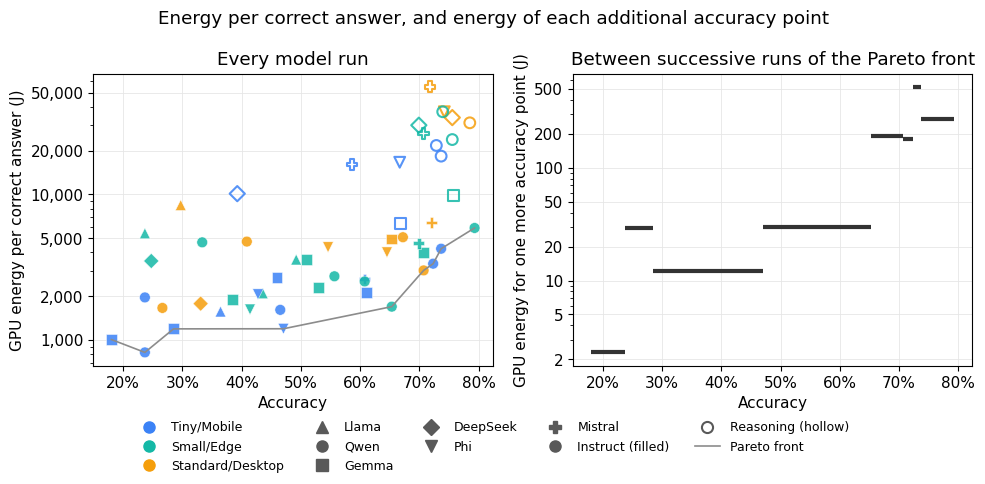

,From,To,Accuracy from,Accuracy to,Energy from (J),Energy to (J),Accuracy points,Joules per accuracy point
0,gemma-1.1-2b-it,Qwen2-1.5B-Instruct,0.180,0.237,184.0,197.0,5.6,2.3
1,Qwen2-1.5B-Instruct,gemma-2-2b-it,0.237,0.285,197.0,339.0,4.8,29.3
2,gemma-2-2b-it,Phi-4-mini-instruct,0.285,0.470,339.0,564.0,18.5,12.1
3,Phi-4-mini-instruct,Qwen3-8B (I),0.470,0.653,564.0,1111.0,18.3,29.9
4,Qwen3-8B (I),Qwen3-14B (I),0.653,0.707,1111.0,2131.0,5.4,189.7
5,Qwen3-14B (I),Qwen3-4B-Instruct-2507,0.707,0.723,2131.0,2425.0,1.6,181.8
6,Qwen3-4B-Instruct-2507,Qwen3.5-4B (I),0.723,0.737,2425.0,3127.0,1.3,523.0
7,Qwen3.5-4B (I),Qwen3.5-9B (I),0.737,0.793,3127.0,4671.0,5.6,273.5


In [7]:
front = pareto_front(model_runs, "gpu_joules_per_question", "accuracy").reset_index(drop=True)
marginal = pd.DataFrame({
    "From": front["model_run"].map(short_name).iloc[:-1].to_numpy(),
    "To": front["model_run"].map(short_name).iloc[1:].to_numpy(),
    "Accuracy from": front["accuracy"].iloc[:-1].to_numpy(),
    "Accuracy to": front["accuracy"].iloc[1:].to_numpy(),
    "Energy from (J)": front["gpu_joules_per_question"].iloc[:-1].to_numpy(),
    "Energy to (J)": front["gpu_joules_per_question"].iloc[1:].to_numpy(),
})
marginal["Accuracy points"] = 100 * (marginal["Accuracy to"] - marginal["Accuracy from"])
marginal["Joules per accuracy point"] = (marginal["Energy to (J)"] - marginal["Energy from (J)"]) / marginal["Accuracy points"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
scatter_model_runs(axes[0], model_runs, "accuracy", "gpu_joules_per_correct_answer")
axes[0].plot(front["accuracy"], front["gpu_joules_per_correct_answer"], color="0.55", linewidth=1.2, zorder=1)
axes[0].set_yscale("log")
plain_log_axis(axes[0].yaxis)
axes[0].set_xlabel("Accuracy")
percent_axis(axes[0].xaxis)
axes[0].set_ylabel("GPU energy per correct answer (J)")
axes[0].set_title("Every model run")

for _, step in marginal.iterrows():
    axes[1].plot([step["Accuracy from"], step["Accuracy to"]], [step["Joules per accuracy point"]] * 2, color="0.2", linewidth=3, solid_capstyle="butt")
axes[1].set_yscale("log")
plain_log_axis(axes[1].yaxis)
axes[1].set_xlim(axes[0].get_xlim())
axes[1].set_xlabel("Accuracy")
percent_axis(axes[1].xaxis)
axes[1].set_ylabel("GPU energy for one more accuracy point (J)")
axes[1].set_title("Between successive runs of the Pareto front")

handles = legend_handles(families=FAMILIES) + [Line2D([], [], color="0.55", linewidth=1.2, label="Pareto front")]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=9, frameon=False)
fig.suptitle("Energy per correct answer, and energy of each additional accuracy point")
plt.tight_layout(rect=(0, 0.11, 1, 1))
save_chart(fig, "rq2-marginal-cost")
plt.show()

marginal.round({"Accuracy from": 3, "Accuracy to": 3, "Energy from (J)": 0, "Energy to (J)": 0, "Accuracy points": 1, "Joules per accuracy point": 1})

### 5. Cost Between Successive Releases
We compare each instruct run with the previous release of the same family, size category and architecture: the change of its accuracy, the change of its GPU energy per question, and the additional energy for each additional accuracy point.

In [8]:
from common import lineages

rows = []
for family, category, architecture, lineage in lineages(model_runs):
    for (_, before), (_, after) in zip(lineage.iloc[:-1].iterrows(), lineage.iloc[1:].iterrows()):
        rows.append({
            "Category": category,
            "Family": family,
            "From": short_name(before["model_run"]),
            "To": short_name(after["model_run"]),
            "To date": after["release_date"],
            "Accuracy points": 100 * (after["accuracy"] - before["accuracy"]),
            "Energy from (J)": before["gpu_joules_per_question"],
            "Energy to (J)": after["gpu_joules_per_question"],
        })
release_steps = pd.DataFrame(rows)
release_steps["Category"] = pd.Categorical(release_steps["Category"], CATEGORY_ORDER, ordered=True)
release_steps = release_steps.sort_values(["Category", "Family", "To date"]).drop(columns=["Family", "To date"]).reset_index(drop=True)
release_steps["Energy ratio"] = release_steps["Energy to (J)"] / release_steps["Energy from (J)"]
more_accurate = release_steps["Accuracy points"] > 0
more_energy = release_steps["Energy ratio"] > 1
# The cost of a point is only defined for the steps that are more accurate with more energy
release_steps["Joules per accuracy point"] = ((release_steps["Energy to (J)"] - release_steps["Energy from (J)"]) / release_steps["Accuracy points"]).where(more_accurate & more_energy)
paid = release_steps[more_accurate & more_energy]
print(f"Steps: {len(release_steps)}; more accurate: {more_accurate.sum()}; more energy per question: {more_energy.sum()}")
print(f"More accurate with more energy: {len(paid)}; more accurate with less energy: {(more_accurate & ~more_energy).sum()}")
print(f"Additional energy per additional accuracy point, in the steps that are more accurate with more energy: {paid['Joules per accuracy point'].min():.0f} J to {paid['Joules per accuracy point'].max():.0f} J (median {paid['Joules per accuracy point'].median():.0f} J)")
print(f"Energy ratio of the steps: {release_steps['Energy ratio'].min():.2f} to {release_steps['Energy ratio'].max():.2f} (median {release_steps['Energy ratio'].median():.2f})")

release_steps.round({"Accuracy points": 1, "Energy from (J)": 0, "Energy to (J)": 0, "Energy ratio": 2, "Joules per accuracy point": 1})

Steps: 18; more accurate: 17; more energy per question: 12
More accurate with more energy: 12; more accurate with less energy: 5
Additional energy per additional accuracy point, in the steps that are more accurate with more energy: 2 J to 523 J (median 51 J)
Energy ratio of the steps: 0.42 to 4.20 (median 1.42)


,Category,From,To,Accuracy points,Energy from (J),Energy to (J),Energy ratio,Joules per accuracy point
0,Tiny/Mobile,gemma-1.1-2b-it,gemma-2-2b-it,10.5,184.0,339.0,1.84,14.8
1,Tiny/Mobile,gemma-2-2b-it,gemma-3-4b-it,17.5,339.0,1232.0,3.63,51.1
2,Tiny/Mobile,Phi-3.5-mini-instruct,Phi-4-mini-instruct,4.3,885.0,564.0,0.64,NaN
3,Tiny/Mobile,Qwen1.5-4B-Chat,Qwen2-1.5B-Instruct,0.0,466.0,197.0,0.42,NaN
4,Tiny/Mobile,Qwen2-1.5B-Instruct,Qwen2.5-3B-Instruct,22.8,197.0,752.0,3.82,24.3
5,Tiny/Mobile,Qwen2.5-3B-Instruct,Qwen3-4B-Instruct-2507,25.8,752.0,2425.0,3.22,64.8
6,Tiny/Mobile,Qwen3-4B-Instruct-2507,Qwen3.5-4B (I),1.3,2425.0,3127.0,1.29,523.0
7,Small/Edge,gemma-1.1-7b-it,gemma-2-9b-it,14.5,728.0,1221.0,1.68,34.0
8,Small/Edge,gemma-3n-E4B-it,gemma-4-E4B-it (I),19.8,1820.0,2824.0,1.55,50.8
9,Small/Edge,Llama-2-7b-chat-hf,Meta-Llama-3-8B-Instruct,19.9,1280.0,914.0,0.71,NaN


### 6. Accuracy and Energy of the Instruct Runs
We compute the rank correlation (Spearman) between the accuracy of the instruct runs and their GPU energy per question, its two factors and their size.

In [9]:
from scipy.stats import spearmanr

instruct_runs = model_runs[model_runs["mode"] == "Instruct"]
COLUMNS = {
    "GPU energy per question": "gpu_joules_per_question",
    "Generated tokens per question": "generated_tokens_per_question",
    "GPU energy per generated token": "gpu_joules_per_generated_token",
    "Active parameters": "activated_parameters",
    "Total parameters": "total_parameters",
}
rows = []
for name, column in COLUMNS.items():
    correlation, p_value = spearmanr(instruct_runs["accuracy"], instruct_runs[column])
    rows.append({"Accuracy against": name, "Instruct runs": len(instruct_runs), "Spearman correlation": round(correlation, 2), "p": round(p_value, 3)})
pd.DataFrame(rows).set_index("Accuracy against")

,Instruct runs,Spearman correlation,p
Accuracy against,,,
GPU energy per question,38,0.79,0.000
Generated tokens per question,38,0.70,0.000
GPU energy per generated token,38,0.45,0.004
Active parameters,38,0.46,0.004
Total parameters,38,0.34,0.039


We repeat the correlation with the generated tokens and with the active parameters within two periods: the instruct runs released before June 2025 and those released since.

In [10]:
PERIODS = {
    "Released before June 2025": instruct_runs["release_date"] < "2025-06-01",
    "Released since June 2025": instruct_runs["release_date"] >= "2025-06-01",
}
rows = []
for period, selected in PERIODS.items():
    runs = instruct_runs[selected]
    for name in ["Generated tokens per question", "Active parameters"]:
        correlation, p_value = spearmanr(runs["accuracy"], runs[COLUMNS[name]])
        rows.append({"Period": period, "Accuracy against": name, "Instruct runs": len(runs), "Spearman correlation": round(correlation, 2), "p": round(p_value, 3)})
pd.DataFrame(rows).set_index(["Period", "Accuracy against"])

Instruct runs  \
Period                    Accuracy against                               
Released before June 2025 Generated tokens per question             29   
                          Active parameters                         29   
Released since June 2025  Generated tokens per question              9   
                          Active parameters                          9   

                                                         Spearman correlation  \
Period                    Accuracy against                                      
Released before June 2025 Generated tokens per question                  0.47   
                          Active parameters                              0.65   
Released since June 2025  Generated tokens per question                  0.68   
                          Active parameters                              0.67   

                                                             p  
Period                    Accuracy against                      
Released before June 2025 Generated tokens per question  0.010  
                          Active parameters              0.000  
Released since June 2025  Generated tokens per question  0.042  
                          Active parameters              0.049

### 7. Key Values

In [11]:
print("Value at the end of each year:")
print(year_end_values.to_string())
print("\nModel run that holds it:")
print(year_end_models.to_string())

print("\nModel runs on the Pareto front:")
print(front.assign(model_run=front["model_run"].map(short_name))[["model_run", "accuracy", "gpu_joules_per_question", "gpu_joules_per_correct_answer"]].round({"accuracy": 3, "gpu_joules_per_question": 0, "gpu_joules_per_correct_answer": 0}).to_string(index=False))
print(f"Energy per question from the first run of the front to the knee and from the knee to the last: {front['gpu_joules_per_question'].iloc[4] - front['gpu_joules_per_question'].iloc[0]:.0f} J and {front['gpu_joules_per_question'].iloc[-1] - front['gpu_joules_per_question'].iloc[4]:.0f} J")

cheapest, costliest = marginal["Joules per accuracy point"].min(), marginal["Joules per accuracy point"].max()
print(f"\nEnergy per additional accuracy point along the front: {cheapest:.1f} J to {costliest:.1f} J ({costliest / cheapest:.0f} times)")
half = model_runs[model_runs["accuracy"] >= 0.5]
print(f"GPU energy per correct answer of the model runs with an accuracy of 0.5 or more: {half['gpu_joules_per_correct_answer'].min():.0f} J to {half['gpu_joules_per_correct_answer'].max():.0f} J")

Value at the end of each year:
Year              2023    2024    2025    2026
Level                                         
Within 0.5 kJ        -   0.285   0.285   0.285
Within 1 kJ      0.247   0.465   0.470   0.470
Within 2 kJ      0.247   0.608   0.653   0.653
Within 5 kJ      0.297   0.672   0.723   0.793
Accuracy of 40%      -   752 J   564 J   564 J
Accuracy of 50%      -  1221 J  1111 J  1111 J
Accuracy of 60%      -  1539 J  1111 J  1111 J
Accuracy of 70%      -       -  2131 J  2131 J

Model run that holds it:
Year                             2023                  2024                    2025                 2026
Level                                                                                                   
Within 0.5 kJ                       -         gemma-2-2b-it           gemma-2-2b-it        gemma-2-2b-it
Within 1 kJ      deepseek-llm-7b-chat   Qwen2.5-3B-Instruct     Phi-4-mini-instruct  Phi-4-mini-instruct
Within 2 kJ      deepseek-llm-7b-chat   Qwen2.5-7B-In